# Small LoRA experiment: adapting a small LM to Amharic

**Author:** Bedru Yimam Ahmed

**Question:** how much does LoRA fine-tuning on a small amount of Amharic text
improve a small open model on Amharic, and does it change English?

**Design**
- Model: `Qwen/Qwen2.5-0.5B` (small, not gated, fits a free Colab T4).
- Training text: Amharic Wikipedia paragraphs (`wikimedia/wikipedia`, `20231101.am`),
  filtered to mostly Ge'ez-script text, with any paragraph that contains a FLORES
  sentence removed.
- Method: LoRA (rank 16) on the attention projections, 1 epoch, fp16 autocast.
- Evaluation: FLORES-200 `devtest`, Amharic **and** English, before vs. after.
- Metric: **bits per character**, not perplexity. Perplexity depends on the
  tokenizer, and the tokenization benchmark shows how much tokenizers differ on
  Amharic. Bits per character is comparable across tokenizers.
- Uncertainty: paired bootstrap over FLORES sentences (same approach as the
  tokenization benchmark).

**Run on a GPU:** Runtime > Change runtime type > T4 GPU. Expect roughly
1-2 hours end to end with the default settings. Lower `N_TRAIN` for a quick test.



In [11]:
!pip -q install -U transformers peft datasets accelerate

In [10]:
!pip install --upgrade torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 55.2 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


## Imports and configuration

In [12]:
import os, re, time, json, math, random, tarfile, urllib.request

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM, get_linear_schedule_with_warmup
from peft import LoraConfig, get_peft_model
from datasets import load_dataset

MODEL_NAME = "Qwen/Qwen2.5-0.5B"
SEED = 42
N_TRAIN = 10000          # Amharic paragraphs used for training
MAX_LEN = 384            # max tokens per training example (incl. start token)
MIN_CHARS = 40           # drop very short paragraphs
GEEZ_RATIO_MIN = 0.6     # keep paragraphs that are mostly Ge'ez script

LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj"]

LR = 2e-4
EPOCHS = 1
BATCH_SIZE = 4
GRAD_ACC = 4             # effective batch = BATCH_SIZE * GRAD_ACC
WARMUP_RATIO = 0.05

EVAL_BATCH = 4
N_EVAL = None            # None = all 1,012 FLORES sentences; e.g. 200 for a quick test
N_BOOT = 2000

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "NO GPU (switch runtime to T4)")

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs("results", exist_ok=True)

Device: cuda | Tesla T4


## Helper functions (no model needed)

`bits_per_char` converts total negative log-likelihood (in nats) to bits per
character. `bootstrap_bpc` resamples sentences **in pairs** (the same sentences
before and after training), so the before/after comparison keeps its pairing.

In [13]:
LN2 = math.log(2)

def geez_ratio(s):
    """Fraction of non-space characters in the Ethiopic Unicode block."""
    letters = [c for c in s if not c.isspace()]
    if not letters:
        return 0.0
    return sum(1 for c in letters if "\u1200" <= c <= "\u137f") / len(letters)

def clean_paragraphs(texts, min_chars=MIN_CHARS, min_ratio=GEEZ_RATIO_MIN):
    """Split documents into paragraphs and keep long, mostly-Ge'ez ones (deduplicated)."""
    seen, out = set(), []
    for t in texts:
        for p in t.split("\n"):
            p = p.strip()
            if len(p) >= min_chars and geez_ratio(p) >= min_ratio and p not in seen:
                seen.add(p)
                out.append(p)
    return out

def bits_per_char(nll_nats, chars):
    """Corpus-level bits per character from per-sentence NLL (nats) and char counts."""
    return float(np.sum(nll_nats) / np.sum(chars) / LN2)

def bootstrap_bpc(nll_before, nll_after, chars, n_boot=N_BOOT, seed=0, conf=0.95):
    """Paired bootstrap over sentences for before/after bits per character."""
    nll_before, nll_after, chars = map(np.asarray, (nll_before, nll_after, chars))
    n = len(chars)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n, size=(n_boot, n))
    c = chars[idx].sum(axis=1)
    b = nll_before[idx].sum(axis=1) / c / LN2
    a = nll_after[idx].sum(axis=1) / c / LN2
    lo, hi = (1 - conf) / 2 * 100, (1 + conf) / 2 * 100
    b0, a0 = bits_per_char(nll_before, chars), bits_per_char(nll_after, chars)
    rel_boot = (a - b) / b * 100
    return {
        "before": b0, "before_lo": float(np.percentile(b, lo)), "before_hi": float(np.percentile(b, hi)),
        "after": a0,  "after_lo": float(np.percentile(a, lo)),  "after_hi": float(np.percentile(a, hi)),
        "delta": a0 - b0,
        "delta_lo": float(np.percentile(a - b, lo)), "delta_hi": float(np.percentile(a - b, hi)),
        "rel_change_pct": (a0 - b0) / b0 * 100,
        "rel_lo": float(np.percentile(rel_boot, lo)), "rel_hi": float(np.percentile(rel_boot, hi)),
    }

## Data

**FLORES-200 `devtest`** is used for evaluation only (never for training). It is
downloaded once from Meta's official release.

**Training text** is Amharic Wikipedia. If the dataset id below fails (names on the
Hub change), find another Amharic text corpus on huggingface.co/datasets and edit
`load_train_paragraphs`.

In [14]:
FLORES_URL = "https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz"

def load_flores(split="devtest", cache_dir="flores200"):
    root = os.path.join(cache_dir, "flores200_dataset")
    if not os.path.isdir(root):
        os.makedirs(cache_dir, exist_ok=True)
        archive = os.path.join(cache_dir, "flores200_dataset.tar.gz")
        if not os.path.exists(archive):
            print("Downloading FLORES-200 ...")
            urllib.request.urlretrieve(FLORES_URL, archive)
        with tarfile.open(archive) as tar:
            tar.extractall(cache_dir)
    def read(code):
        with open(os.path.join(root, split, f"{code}.{split}"), encoding="utf-8") as f:
            return [line.rstrip("\n") for line in f]
    return read("amh_Ethi"), read("eng_Latn")

am_texts, en_texts = load_flores()
assert len(am_texts) == len(en_texts)
if N_EVAL is not None:
    am_texts, en_texts = am_texts[:N_EVAL], en_texts[:N_EVAL]
print("FLORES pairs for evaluation:", len(am_texts))
print("AM[0]:", am_texts[0]); print("EN[0]:", en_texts[0])

FLORES pairs for evaluation: 1012
AM[0]: "አሁን የስኳር በሽተኛ ያልነበሩ አሁን ግን የሆኑ የ4-ወር-ዕድሜ ያላቸው አይጦች አሉን፣ አለ። "
EN[0]: "We now have 4-month-old mice that are non-diabetic that used to be diabetic," he added.


In [15]:
TRAIN_SOURCE = "wikimedia/wikipedia (20231101.am)"

def load_train_paragraphs():
    try:
        ds = load_dataset("wikimedia/wikipedia", "20231101.am", split="train")
    except Exception as e:
        raise RuntimeError(
            "Could not load Amharic Wikipedia. Pick another Amharic text dataset on the "
            "Hugging Face Hub and edit this function. Original error: " + repr(e))
    return clean_paragraphs(ds["text"])

paragraphs = load_train_paragraphs()
print("Clean Amharic paragraphs available:", len(paragraphs))

# Leakage check: drop any paragraph that contains a FLORES devtest sentence (exact match).
flores_sentences = [s.strip() for s in am_texts if len(s.strip()) >= 20]
before = len(paragraphs)
paragraphs = [p for p in paragraphs if not any(s in p for s in flores_sentences)]
print(f"Removed {before - len(paragraphs)} paragraphs overlapping FLORES")

rng = random.Random(SEED)
rng.shuffle(paragraphs)
train_paragraphs = paragraphs[:N_TRAIN]
print("Training paragraphs used:", len(train_paragraphs))
print("Example:", train_paragraphs[0][:150])

Clean Amharic paragraphs available: 39134
Removed 0 paragraphs overlapping FLORES
Training paragraphs used: 10000
Example: በአውሮፓ ውስጥ ያሉት መንግሥታት ሃይማኖቶች ወይም ቀድሞ የነበሯቸው ሃይማኖቶች


## Load the base model and evaluate it BEFORE training

For each sentence the model scores every token given the previous ones; the first
token is conditioned on a single start token (Qwen has no BOS token, so the
end-of-text token is used). Sentences are not truncated, so the character count
always matches the scored text.

In [16]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
START_ID = tokenizer.bos_token_id if tokenizer.bos_token_id is not None else tokenizer.eos_token_id

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float32).to(device)
print("Parameters:", sum(p.numel() for p in model.parameters()) / 1e6, "M")


@torch.no_grad()
def sentence_nll(model, texts, batch_size=EVAL_BATCH):
    """Per-sentence total NLL in nats, plus scored-token counts."""
    model.eval()
    enc = [[START_ID] + tokenizer.encode(t, add_special_tokens=False) for t in texts]
    order = np.argsort([len(e) for e in enc])
    nll = np.zeros(len(texts)); ntok = np.zeros(len(texts), dtype=int)
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size]
        batch = [enc[j] for j in idx]
        L = max(len(b) for b in batch)
        ids = torch.full((len(batch), L), tokenizer.pad_token_id, dtype=torch.long)
        mask = torch.zeros((len(batch), L), dtype=torch.long)
        for r, b in enumerate(batch):
            ids[r, :len(b)] = torch.tensor(b)
            mask[r, :len(b)] = 1
        ids, mask = ids.to(device), mask.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            logits = model(input_ids=ids, attention_mask=mask).logits
        V = logits.size(-1)
        tok_nll = torch.nn.functional.cross_entropy(
            logits[:, :-1].float().reshape(-1, V), ids[:, 1:].reshape(-1), reduction="none"
        ).view(len(batch), L - 1)
        tok_mask = mask[:, 1:].float()
        s = (tok_nll * tok_mask).sum(1).cpu().numpy()
        for r, j in enumerate(idx):
            nll[j] = s[r]; ntok[j] = int(tok_mask[r].sum().item())
    return nll, ntok


am_chars = np.array([len(t) for t in am_texts]); en_chars = np.array([len(t) for t in en_texts])

t0 = time.time()
am_nll_before, am_ntok = sentence_nll(model, am_texts)
en_nll_before, en_ntok = sentence_nll(model, en_texts)
print(f"Eval time: {(time.time() - t0) / 60:.1f} min")
print(f"BEFORE  Amharic bits/char: {bits_per_char(am_nll_before, am_chars):.3f} | "
      f"English bits/char: {bits_per_char(en_nll_before, en_chars):.3f}")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Parameters: 494.032768 M
Eval time: 0.8 min
BEFORE  Amharic bits/char: 6.163 | English bits/char: 1.077


### This model's tokenizer on FLORES (links to the tokenization benchmark)

A tokenizer that fragments Amharic means fewer Amharic characters fit in the same
number of training tokens. This reports the same efficiency numbers as the benchmark.

In [17]:
am_tok = int(am_ntok.sum()); en_tok = int(en_ntok.sum())   # scored tokens (excludes start token)
am_words = sum(len(t.split()) for t in am_texts); en_words = sum(len(t.split()) for t in en_texts)
am_bytes = sum(len(t.encode("utf-8")) for t in am_texts); en_bytes = sum(len(t.encode("utf-8")) for t in en_texts)

tok_stats = pd.DataFrame({
    "Language": ["Amharic", "English"],
    "Fertility (tokens/word)": [am_tok / am_words, en_tok / en_words],
    "Chars per token": [am_chars.sum() / am_tok, en_chars.sum() / en_tok],
    "Tokens per byte": [am_tok / am_bytes, en_tok / en_bytes],
}).round(3)
print(f"Tokenizer: {MODEL_NAME}")
tok_stats

Tokenizer: Qwen/Qwen2.5-0.5B


,Language,Fertility (tokens/word),Chars per token,Tokens per byte
0,Amharic,6.448,0.780,0.496
1,English,1.261,4.778,0.209


## LoRA fine-tuning

Only the small LoRA matrices are trained; the base weights stay frozen. The model is
kept in fp32 with fp16 autocast and a gradient scaler, which works on a T4 (no bf16).

In [18]:
def encode_train(text):
    ids = tokenizer.encode(text, add_special_tokens=False)[:MAX_LEN - 1]
    return [START_ID] + ids

train_ids = [encode_train(p) for p in train_paragraphs]
train_tokens = sum(len(x) - 1 for x in train_ids)
train_chars_full = sum(len(p) for p in train_paragraphs)
print(f"Training examples: {len(train_ids)} | training tokens (after truncation): {train_tokens/1e6:.2f}M")
print(f"Paragraphs truncated at {MAX_LEN} tokens: "
      f"{sum(1 for p in train_paragraphs if len(tokenizer.encode(p, add_special_tokens=False)) > MAX_LEN - 1)}")

def collate(batch):
    L = max(len(b) for b in batch)
    ids = torch.full((len(batch), L), tokenizer.pad_token_id, dtype=torch.long)
    mask = torch.zeros((len(batch), L), dtype=torch.long)
    labels = torch.full((len(batch), L), -100, dtype=torch.long)
    for r, b in enumerate(batch):
        t = torch.tensor(b)
        ids[r, :len(b)] = t; mask[r, :len(b)] = 1
        labels[r, 1:len(b)] = t[1:]          # do not train on predicting from nothing
    return {"input_ids": ids, "attention_mask": mask, "labels": labels}

g = torch.Generator(); g.manual_seed(SEED)
loader = torch.utils.data.DataLoader(train_ids, batch_size=BATCH_SIZE, shuffle=True,
                                     collate_fn=collate, generator=g)

lora_cfg = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                      target_modules=TARGET_MODULES, bias="none", task_type="CAUSAL_LM")
model = get_peft_model(model, lora_cfg)
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in model.parameters())
print(f"Trainable params: {n_trainable/1e6:.2f}M of {n_total/1e6:.1f}M total ({100*n_trainable/n_total:.2f}%)")

Training examples: 10000 | training tokens (after truncation): 1.78M


Paragraphs truncated at 384 tokens: 1574
Trainable params: 2.16M of 496.2M total (0.44%)


In [19]:
params = [p for p in model.parameters() if p.requires_grad]
opt = torch.optim.AdamW(params, lr=LR, weight_decay=0.0)
steps_per_epoch = math.ceil(len(loader) / GRAD_ACC)
total_steps = steps_per_epoch * EPOCHS
sched = get_linear_schedule_with_warmup(opt, int(WARMUP_RATIO * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

model.config.use_cache = False
model.train()
loss_log, running, running_n, step = [], 0.0, 0, 0
t_train = time.time()

for epoch in range(EPOCHS):
    for i, batch in enumerate(loader):
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            loss = model(**batch).loss
        scaler.scale(loss / GRAD_ACC).backward()
        running += loss.item(); running_n += 1

        if (i + 1) % GRAD_ACC == 0 or (i + 1) == len(loader):
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update()
            opt.zero_grad(set_to_none=True); sched.step(); step += 1
            if step % 25 == 0 or step == total_steps:
                avg = running / running_n
                loss_log.append((step, avg))
                print(f"step {step}/{total_steps} | loss {avg:.4f} | {(time.time()-t_train)/60:.1f} min")
                running, running_n = 0.0, 0

train_minutes = (time.time() - t_train) / 60
print(f"Training finished in {train_minutes:.1f} min")

/tmp/ipykernel_1335/2085936291.py:25: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  opt.zero_grad(set_to_none=True); sched.step(); step += 1


step 25/625 | loss 3.2108 | 0.6 min
step 50/625 | loss 2.8999 | 1.2 min
step 75/625 | loss 2.6821 | 1.7 min
step 100/625 | loss 2.5993 | 2.4 min
step 125/625 | loss 2.5420 | 2.9 min
step 150/625 | loss 2.5026 | 3.4 min
step 175/625 | loss 2.4861 | 3.9 min
step 200/625 | loss 2.4373 | 4.4 min
step 225/625 | loss 2.4361 | 4.9 min
step 250/625 | loss 2.4158 | 5.4 min
step 275/625 | loss 2.3959 | 5.9 min
step 300/625 | loss 2.3735 | 6.4 min
step 325/625 | loss 2.3556 | 6.9 min
step 350/625 | loss 2.3600 | 7.4 min
step 375/625 | loss 2.3278 | 8.0 min
step 400/625 | loss 2.3159 | 8.4 min
step 425/625 | loss 2.3009 | 9.0 min
step 450/625 | loss 2.2872 | 9.4 min
step 475/625 | loss 2.2921 | 9.9 min
step 500/625 | loss 2.2921 | 10.4 min
step 525/625 | loss 2.2705 | 10.9 min
step 550/625 | loss 2.2581 | 11.5 min
step 575/625 | loss 2.2544 | 12.0 min
step 600/625 | loss 2.2616 | 12.5 min
step 625/625 | loss 2.2392 | 13.0 min
Training finished in 13.0 min


## Evaluate AFTER training (same FLORES sentences)

In [20]:
model.config.use_cache = True
am_nll_after, _ = sentence_nll(model, am_texts)
en_nll_after, _ = sentence_nll(model, en_texts)
print(f"AFTER   Amharic bits/char: {bits_per_char(am_nll_after, am_chars):.3f} | "
      f"English bits/char: {bits_per_char(en_nll_after, en_chars):.3f}")

AFTER   Amharic bits/char: 4.248 | English bits/char: 1.279


## Results table (paired bootstrap 95% CIs)

Lower bits per character is better. A negative change means the model got better.
The English row is a forgetting check: if it rises, the adapter is hurting English.

In [21]:
res_am = bootstrap_bpc(am_nll_before, am_nll_after, am_chars)
res_en = bootstrap_bpc(en_nll_before, en_nll_after, en_chars)

def row(lang, r, n):
    return {
        "Language": lang, "N sentences": n,
        "Bits/char before": round(r["before"], 3),
        "Bits/char after": round(r["after"], 3),
        "Change (bits/char)": round(r["delta"], 3),
        "Change 95% CI": f"[{r['delta_lo']:.3f}, {r['delta_hi']:.3f}]",
        "Relative change (%)": round(r["rel_change_pct"], 2),
        "Rel. change 95% CI (%)": f"[{r['rel_lo']:.2f}, {r['rel_hi']:.2f}]",
    }

results_df = pd.DataFrame([row("Amharic", res_am, len(am_texts)), row("English", res_en, len(en_texts))])
results_df.to_csv("results/lora_results.csv", index=False)

run_config = {
    "model": MODEL_NAME, "seed": SEED, "train_source": TRAIN_SOURCE,
    "n_train_paragraphs": len(train_paragraphs), "train_tokens": train_tokens,
    "max_len": MAX_LEN, "lora_r": LORA_R, "lora_alpha": LORA_ALPHA, "lora_dropout": LORA_DROPOUT,
    "target_modules": TARGET_MODULES, "lr": LR, "epochs": EPOCHS,
    "batch_size": BATCH_SIZE, "grad_acc": GRAD_ACC, "steps": total_steps,
    "trainable_params": n_trainable, "total_params": n_total,
    "train_minutes": round(train_minutes, 1),
    "gpu": torch.cuda.get_device_name(0) if device == "cuda" else "cpu",
    "torch": torch.__version__, "eval_dataset": "FLORES-200 devtest", "eval_pairs": len(am_texts),
}
json.dump(run_config, open("results/lora_run_config.json", "w"), indent=2)
results_df

,Language,N sentences,Bits/char before,Bits/char after,Change (bits/char),Change 95% CI,Relative change (%),Rel. change 95% CI (%)
0,Amharic,1012,6.163,4.248,-1.915,"[-1.944, -1.887]",-31.07,"[-31.40, -30.74]"
1,English,1012,1.077,1.279,0.202,"[0.197, 0.207]",18.76,"[18.22, 19.26]"


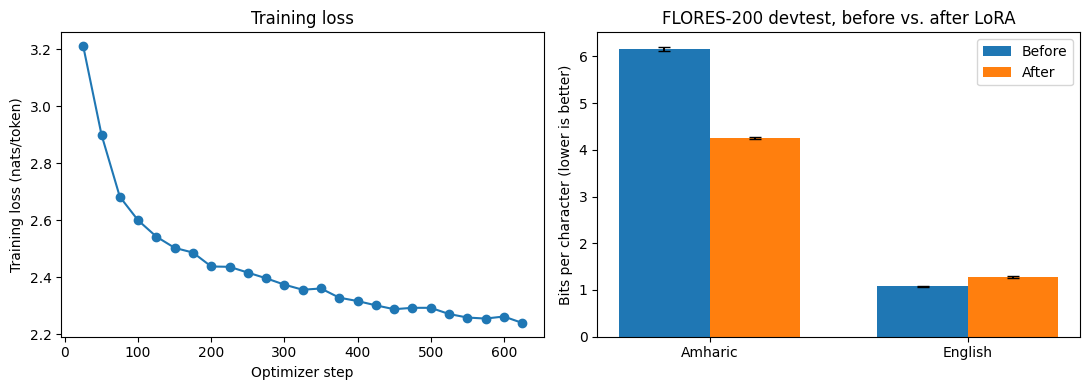

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

steps_, losses_ = zip(*loss_log) if loss_log else ([], [])
ax[0].plot(steps_, losses_, marker="o")
ax[0].set_xlabel("Optimizer step"); ax[0].set_ylabel("Training loss (nats/token)")
ax[0].set_title("Training loss")

x = np.arange(2); w = 0.35
for k, (lbl, key) in enumerate([("Before", "before"), ("After", "after")]):
    vals = [res_am[key], res_en[key]]
    err = [[res_am[key] - res_am[key + "_lo"], res_en[key] - res_en[key + "_lo"]],
           [res_am[key + "_hi"] - res_am[key], res_en[key + "_hi"] - res_en[key]]]
    ax[1].bar(x + (k - 0.5) * w, vals, w, yerr=err, capsize=4, label=lbl)
ax[1].set_xticks(x); ax[1].set_xticklabels(["Amharic", "English"])
ax[1].set_ylabel("Bits per character (lower is better)")
ax[1].set_title("FLORES-200 devtest, before vs. after LoRA"); ax[1].legend()
plt.tight_layout()
plt.savefig("results/lora_before_after.png", dpi=150)
plt.show()

## Text for your CV and README (generated from this run's numbers)

Read it, keep the wording honest, and only add claims the numbers support.

In [23]:
def direction(r):
    return "decreased" if r["delta"] < 0 else "increased"

cv_line = (
    f"LoRA adaptation for Amharic (2026): Fine-tuned {MODEL_NAME.split('/')[-1]} with LoRA "
    f"(rank {LORA_R}; {n_trainable/1e6:.1f}M trainable parameters, {100*n_trainable/n_total:.1f}% of the model) "
    f"on {len(train_paragraphs):,} Amharic Wikipedia paragraphs ({train_tokens/1e6:.1f}M tokens). "
    f"On FLORES-200 devtest, Amharic bits per character {direction(res_am)} from "
    f"{res_am['before']:.3f} to {res_am['after']:.3f} ({res_am['rel_change_pct']:+.1f}%, "
    f"95% CI {res_am['rel_lo']:+.1f} to {res_am['rel_hi']:+.1f}%); English {direction(res_en)} from "
    f"{res_en['before']:.3f} to {res_en['after']:.3f} ({res_en['rel_change_pct']:+.1f}%). "
    f"Trained in {train_minutes:.0f} min on one {run_config['gpu']}."
)
print("CV BULLET\n" + cv_line)

print("\nREADME TABLE ROW")
print("| Model | Trainable params | Amharic bits/char (before -> after) | English bits/char (before -> after) | Training time |")
print("|---|---|---|---|---|")
print(f"| {MODEL_NAME.split('/')[-1]} + LoRA (r={LORA_R}) | {n_trainable/1e6:.1f}M ({100*n_trainable/n_total:.1f}%) | "
      f"{res_am['before']:.3f} -> {res_am['after']:.3f} | {res_en['before']:.3f} -> {res_en['after']:.3f} | "
      f"{train_minutes:.0f} min on {run_config['gpu']} |")

CV BULLET
LoRA adaptation for Amharic (2026): Fine-tuned Qwen2.5-0.5B with LoRA (rank 16; 2.2M trainable parameters, 0.4% of the model) on 10,000 Amharic Wikipedia paragraphs (1.8M tokens). On FLORES-200 devtest, Amharic bits per character decreased from 6.163 to 4.248 (-31.1%, 95% CI -31.4 to -30.7%); English increased from 1.077 to 1.279 (+18.8%). Trained in 13 min on one Tesla T4.

README TABLE ROW
| Model | Trainable params | Amharic bits/char (before -> after) | English bits/char (before -> after) | Training time |
|---|---|---|---|---|
| Qwen2.5-0.5B + LoRA (r=16) | 2.2M (0.4%) | 6.163 -> 4.248 | 1.077 -> 1.279 | 13 min on Tesla T4 |


## Optional: save the adapter

The adapter is small (a few MB). Do not commit it to Git unless you want to.
Download `results/lora_results.csv`, `results/lora_run_config.json` and
`results/lora_before_after.png` from the Colab file panel and add them to your repo.

In [24]:
model.save_pretrained("lora_adapter")
print("Saved adapter to ./lora_adapter")

Saved adapter to ./lora_adapter
